In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

In [7]:
matrix=pd.read_csv("dataset.txt",header=None,names=["Rx","Ry","Rz","P"])

X=matrix[["Rx","Ry","Rz"]]
Y=matrix["P"]

In [8]:
X_train,X_temp,Y_train,Y_temp=train_test_split(X,Y,test_size=0.4,random_state=42)
X_valid,X_test,Y_valid,Y_test=train_test_split(X_temp,Y_temp,test_size=0.5,random_state=42)

print("Train:",X_train.shape,Y_train.shape)
print("Valid:",X_valid.shape,Y_train.shape)
print("Test:",X_test.shape,Y_test.shape)

Train: (14, 3) (14,)
Valid: (5, 3) (14,)
Test: (5, 3) (5,)


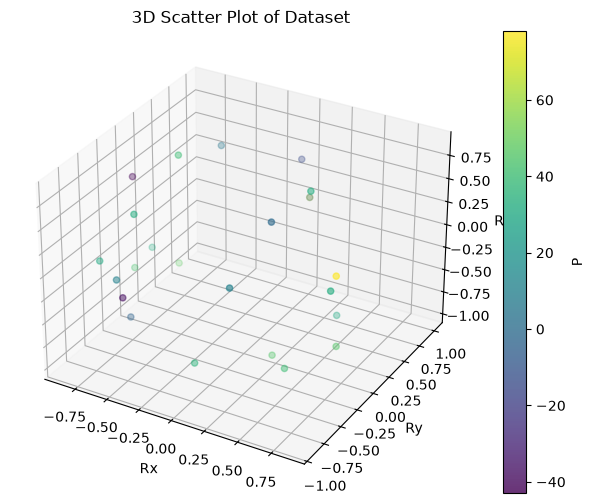

In [15]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

# Scatter plot of Rx, Ry, Rz colored by target P
scatter = ax.scatter(
    matrix["Rx"],
    matrix["Ry"],
    matrix["Rz"],
    c=matrix["P"],  # Color by class/value in P
    cmap="viridis",  # Color palette
    alpha=0.8,
)

ax.set_xlabel("Rx")
ax.set_ylabel("Ry")
ax.set_zlabel("Rz")
ax.set_title("3D Scatter Plot of Dataset")

# Add colorbar / legend
plt.colorbar(scatter, ax=ax, label="P")
plt.show()


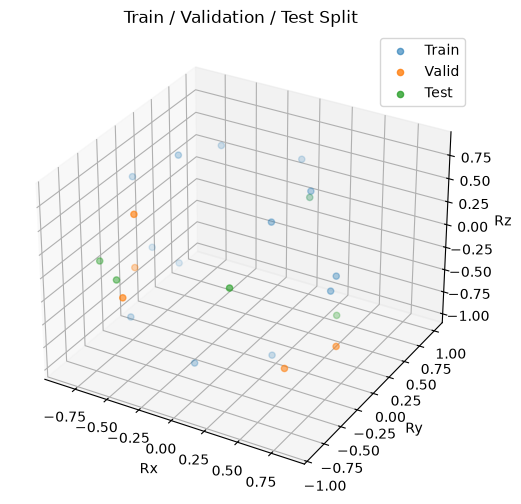

In [16]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X_train["Rx"], X_train["Ry"], X_train["Rz"], label="Train", alpha=0.6
)
ax.scatter(
    X_valid["Rx"], X_valid["Ry"], X_valid["Rz"], label="Valid", alpha=0.8
)
ax.scatter(X_test["Rx"], X_test["Ry"], X_test["Rz"], label="Test", alpha=0.8)

ax.set_xlabel("Rx")
ax.set_ylabel("Ry")
ax.set_zlabel("Rz")
ax.set_title("Train / Validation / Test Split")
ax.legend()
plt.show()


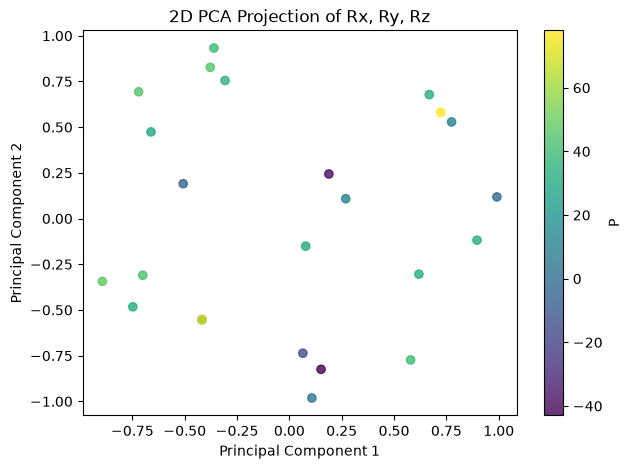

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=Y, cmap="viridis", alpha=0.8)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Projection of Rx, Ry, Rz")
plt.colorbar(scatter, label="P")
plt.show()

In [25]:
svm_regressor=SVR(kernel='linear',C=1.0)
svm_regressor.fit(X_train,Y_train)
y_pred=svm_classifier.predict(X_test)

In [27]:
print('R2 Score:', r2_score(Y_test, y_pred))
print('MSE:', mean_squared_error(Y_test, y_pred))

R2 Score: -0.10778509597534391
MSE: 529.0652212931958


c:\Users\TEJAS\OneDrive\Desktop\test\pandas_1\.venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


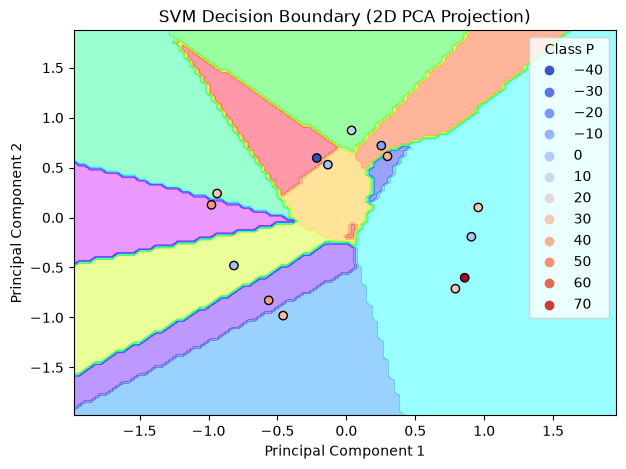

In [30]:
# 1. Reduce 3D features to 2D
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
Y_discrete = Y_train.astype(int)

# 2. Fit SVC on PCA features
svm_pca = SVC(kernel="linear", C=1.0)
svm_pca.fit(X_train_pca, Y_discrete)

# 3. Plot decision boundary
fig, ax = plt.subplots(figsize=(7, 5))

DecisionBoundaryDisplay.from_estimator(
    svm_pca,
    X_train_pca,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.4,
    ax=ax,
)

scatter = ax.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=Y_discrete,
    cmap=plt.cm.coolwarm,
    edgecolors="k",
)

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title("SVM Decision Boundary (2D PCA Projection)")
plt.legend(*scatter.legend_elements(), title="Class P")
plt.show()